In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()

print("Qiskit environment is ready.")

Qiskit environment is ready.


# **Quantum Teleporation**

## 1. **What is quantum teleportation?**

Suppose Alice possesses a qubit in an unknown quantum state:

$$
|\psi\rangle = \alpha|0\rangle+\beta|1\rangle
$$

where

$$
|\alpha|^2+|\beta|^2=1.
$$

Alice wants Bob to obtain this quantum state, even though they are physically separated.

Quantum teleportation allows Alice to transfer the **quantum state** to Bob using:

1. A shared entangled pair.
2. A joint operation and measurement by Alice.
3. Two classical bits sent from Alice to Bob.
4. Correction gates applied by Bob.

Alice does not send the original qubit to Bob. After Alice's measurement, the original state is no longer available on her input qubit.

### The three qubits

We will use three qubits:

- $q_0$: Alice's original state $|\psi\rangle$.
- $q_1$: Alice's half of the shared entangled pair.
- $q_2$: Bob's half of the shared entangled pair.

Initially,

$$
|\psi\rangle_{q_0}|0\rangle_{q_1}|0\rangle_{q_2}.
$$

Alice and Bob first create a Bell pair between $q_1$ and $q_2$:

$$
|\Phi^+\rangle
=
\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

The shared state is then

$$
|\psi\rangle_{q_0}\otimes
\frac{|00\rangle_{q_1q_2}+|11\rangle_{q_1q_2}}{\sqrt{2}}.
$$

**Important:** Alice and Bob need to share the entangled pair before the teleportation protocol begins.

### 1.1. The Teleportation Circuit

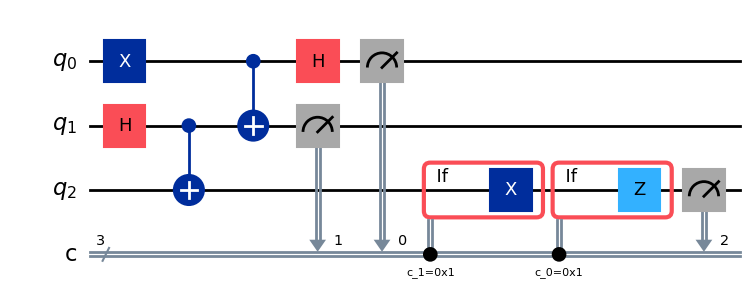

In [3]:
qc_teleport_diagram = QuantumCircuit(3, 3)

# Prepare an example input state |1>
qc_teleport_diagram.x(0)

# Create a Bell pair between Alice's q1 and Bob's q2
qc_teleport_diagram.h(1)
qc_teleport_diagram.cx(1, 2)

# Alice's Bell-basis measurement circuit
qc_teleport_diagram.cx(0, 1)
qc_teleport_diagram.h(0)

# Alice measures her two qubits
qc_teleport_diagram.measure(0, 0)
qc_teleport_diagram.measure(1, 1)

# Bob's corrections, controlled by Alice's classical results
with qc_teleport_diagram.if_test((qc_teleport_diagram.clbits[1], 1)):
    qc_teleport_diagram.x(2)

with qc_teleport_diagram.if_test((qc_teleport_diagram.clbits[0], 1)):
    qc_teleport_diagram.z(2)

# Bob measures his qubit
qc_teleport_diagram.measure(2, 2)

display(qc_teleport_diagram.draw("mpl", fold=-1))